In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import scipy
import scipy.spatial
import scipy.spatial.distance


In [4]:
with open("X.trc", "rb") as f:
    X = torch.load(f)
with open("Y.trc", "rb") as f:
    Y = torch.load(f)
X = X.numpy()
Y = Y.numpy()

/tmp/ipykernel_13689/979828780.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  X = torch.load(f)
/tmp/ipykernel_13689/979828780.py:4: FutureWarning: You are using `torch

In [5]:
print(X.shape)
print(Y.shape)

(8326, 24)
(8326, 960)


In [6]:
# samples = np.random.choice(X.shape[0], size=50000, replace=False)
# X_sub = X[samples]
# Y_sub = Y[samples]

X_sub = X
Y_sub = Y

In [7]:
multiplier = np.array([1] * 12 + [1] * 12)

In [8]:
r = 0.9

In [10]:
move_r_mult = 1.1

In [11]:
def compute_diff(X_data, Y_data):
    x_diff = np.ndarray(X_data.shape[0])
    y_diff = np.ndarray(X_data.shape[0])

    tree = scipy.spatial.KDTree(X_data)
    indices = tree.query_ball_point(X_data, r * move_r_mult, workers=-1)
    for i, index in enumerate(indices):
        x_diff[i] = np.linalg.norm(X_data[index].mean(0) - X_data[i])
        y_diff[i] = np.linalg.norm(Y_data[index].mean(0) - Y_data[i])

    return np.array(x_diff).flatten(), np.array(y_diff).flatten()

In [12]:
X_data, Y_data = X_sub, Y_sub
cum = 1
for i in range(30, 8, -1):
    x_diff, y_diff = compute_diff(X_data, Y_data)
    condition = y_diff < i
    X_data, Y_data = X_data[condition], Y_data[condition]
    cum *= condition.mean()
    print(i, cum, condition.mean())

30 1.0 1.0
29 1.0 1.0
28 0.9998798943069902 0.9998798943069902
27 0.9998798943069902 1.0
26 0.9996396829209705 0.9997597597597597
25 0.9995195772279606 0.9998798510152589
24 0.9990391544559212 0.9995193463109829
23 0.9989190487629113 0.9998797787929791
22 0.9984386259908719 0.9995190573524108
21 0.9973576747537832 0.9989173583543847
20 0.9956761950516454 0.9983140655105973
19 0.9939947153495075 0.9983112183353438
18 0.9933941868844582 0.99939584340261
17 0.9921931299543597 0.9987909563535243
16 0.990391544559212 0.9981842391962232
15 0.989550804708143 0.9991511035653651
14 0.9877492193129953 0.9981793907027552
13 0.9858275282248378 0.9980544747081712
12 0.9839058371366801 0.9980506822612085
11 0.9815037232764832 0.99755859375
10 0.9777804467931779 0.9962065589818894
9 0.9700936824405476 0.9921385579167179


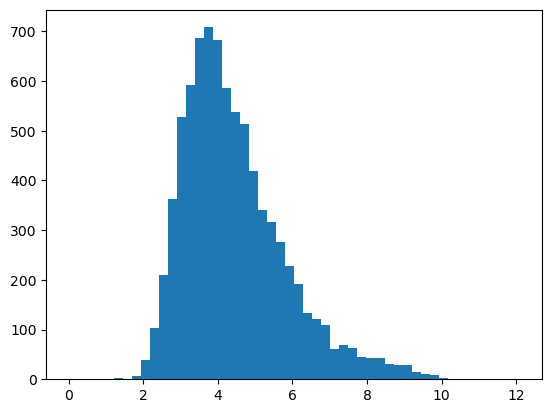

8077


In [13]:
plt.hist(y_diff, bins=50)
plt.show()
print(len(X_data))
with open("X_filtered.trc", "wb") as f:
    torch.save(torch.tensor(X_data), f)
with open("Y_filtered.trc", "wb") as f:
    torch.save(torch.tensor(Y_data), f)

8326
1.0


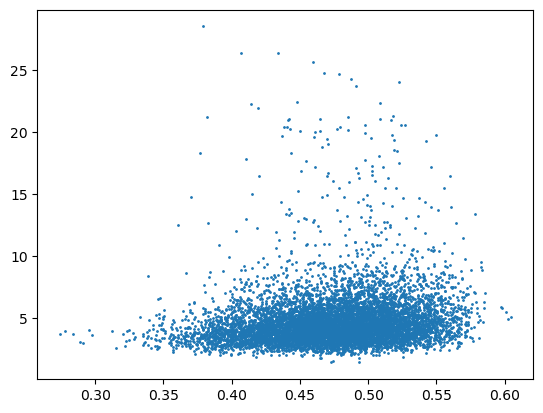

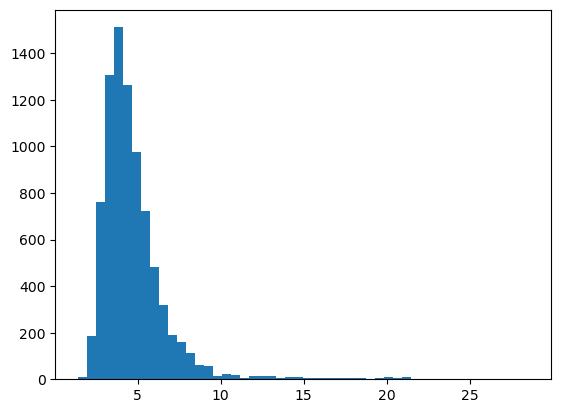

In [14]:
x_diff, y_diff = compute_diff(X, Y)

condition = y_diff < 100
X_data, Y_data = torch.tensor(X[condition]), torch.tensor(Y[condition])
print(len(X_data))
print(condition.mean())

plt.scatter(x_diff[condition], y_diff[condition], s=1)
plt.show()

plt.hist(y_diff[condition], bins=50)
plt.show()


# with open("X_filtered.trc", "wb") as f:
#     torch.save(torch.tensor(X[condition]), f)
# with open("Y_filtered.trc", "wb") as f:
#     torch.save(torch.tensor(Y[condition]), f)


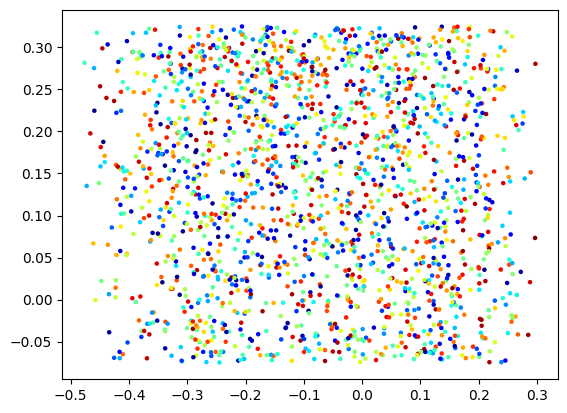

In [27]:
for i in range(0, 1):
    x = []
    y = []
    # z = []
    c = []
    for x_val, y_val in zip(X[condition], Y[condition]):
        x.append(x_val[0])
        y.append(x_val[1])
        # z.append(x_val[2])
        c.append(y_val[i])

    fig = plt.figure()
    ax = fig.add_subplot()
    ax.scatter(x, y, c=c, alpha=1, s=5, cmap="jet")
    # plt.savefig(f"test_{i}.png", dpi=1000)
    plt.show()

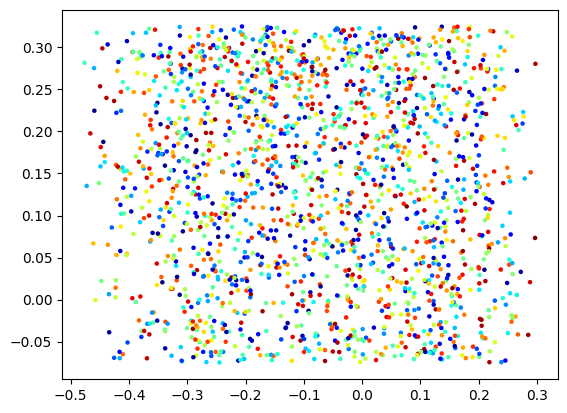

In [28]:
for i in range(0, 1):
    x = []
    y = []
    # z = []
    c = []
    for x_val, y_val in zip(X, Y):
        x.append(x_val[0])
        y.append(x_val[1])
        # z.append(x_val[2])
        c.append(y_val[i])

    fig = plt.figure()
    ax = fig.add_subplot()
    ax.scatter(x, y, c=c, alpha=1, s=5, cmap="jet")
    # plt.savefig(f"test_{i}.png", dpi=1000)
    plt.show()